# HAM10000 Skin Lession Classification - Model Training Notebook
This notebook contains my part of the group project, where I prepare the HAM10000 dataset and train two deep-learning models:
1. Weighted ResNet18 (baseline)
2. MobileNetV2 with focal loss + threshold tuning (improved model)

The notebook includes:
Dataset organization and preprocessing
Class balancing methods
Model training with explanations of each block 
Evaluation using accuracy, confusion matrix, PR curve, and melanoma threshold tuning



## 1. Reproducibility and GPU Check 
This block sets a random seed so the results remain consistent across runs, and checks if a GPU is available.
Reproducibility is essential because deep learning results can vary if seed are not fixed.

In [ ]:
# Set random seed for reproducibility and check if PyTorch can use the GPU
import numpy as np
import random
import torch

SEED = 1337
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())
print("GPU device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

## 2. Create Necessary Project Folders
This section build the required folder structure for raw data, processed image data, model outputs, and checkpoints.
Organizing the project early prevents path issues later in training.

In [2]:
# Create all required directories for raw data, processed data, and model output.
from pathlib import Path

BASE_DIR = Path("/content/ham_pytorch")
RAW_DIR = BASE_DIR/"data/raw"
IMG_DIR = RAW_DIR/"images"
PROC_DIR = BASE_DIR/"data/processed"
OUT_DIR = BASE_DIR/"outputs"

for p in [IMG_DIR, PROC_DIR, OUT_DIR/"metrics", OUT_DIR/"checkpoints"]:
  p.mkdir(parents = True, exist_ok = True)

print("Folder Created Successfully.")
print("\nNow upload your dataset file here:")
print("Metadata.csv", RAW_DIR)
print("Image Files", IMG_DIR)

Folder Created Successfully.

Now upload your dataset file here:
Metadata.csv /content/ham_pytorch/data/raw
Image Files /content/ham_pytorch/data/raw/images


## 3. Mount Google Drive
Mount Google Drive to acess HAM10000 dataset that is stored there.
This allows the notebook to copy metadata and image file into working directory.

In [3]:
# Mount Google Drive so the HAM10000 dataset can be accessed in colab.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 4. Copy Dataset Files Into the Project Folder
This block automatically detects the HAM10000 folder, copies metadata, and syncs all images into the project.
The script supports multiple folder structures to avoid errors for different user.

In [4]:
# Locate the HAM10000 dataset in Google Drive and Copy all metadata + images into a project folder
import os, glob, pathlib, subprocess

RAW = "/content/ham_pytorch/data/raw"
IMG = f"{RAW}/images"
pathlib.Path(IMG).mkdir(parents = True, exist_ok = True) # Ensure image directory exists

def find_ham_root():
  # Search for the HAM10000 folder in Google Drive (direct path or recursive search)
    cand = "/content/drive/MyDrive/HAM10000"
    if os.path.isdir(cand):
      return cand

    # If not found, search up to 4 levels deep
    out = subprocess.check_output(["bash", "-lc", "find /content/drive/MyDrive -maxdepth 4 -type d -name HAM10000 2>/dev/null || true"]).decode().strip()
    paths = [p for p in out.splitlines() if p.strip()]
    if not paths:
        raise FileNotFoundError("couldn't find a folder named 'HAM10000' in Google Drive. Create MyDrive/HAM10000 and place files inside.")
    return paths[0]

SRC = find_ham_root()
print("Detected dataset folder:", SRC)

# Copy metadata CSV file
meta_src = f"{SRC}/HAM10000_metadata.csv"
assert os.path.exists(meta_src), f"Metadata not found at {meta_src}"
!cp "{meta_src}" "{RAW}/"

def rsync_dir_if_exists(dname):
  # copy images subfolder if it exists
  cand = os.path.join(SRC, dname)
  if os.path.isdir(cand):
      print("Copying:", cand)
      !rsync -ah --progress "{cand}/" "{IMG}/"
      return True
  return False

# Try common folder names
copied_any = False
copied_any |= rsync_dir_if_exists("HAM10000_images_part_1")
copied_any |= rsync_dir_if_exists("HAM10000_images_part_2")

for alt in ["images_part_1", "images_part_2", "HAM10000_images_part_1", "HAM10000_images_part_2"]:
  copied_any |= rsync_dir_if_exists(alt)

# Fallback: copy all .jpg/.png files recursively
if not copied_any:
  print("No part folders matched. Copying all images under HAM10000 recursively....")
  !rsync -ah --progress \
     --include="*/" \
     --include="*.jpg" \
     --include="*.jpeg" \
     --include="*.png" \
     --exclude="*" \
     "{SRC}/" "{IMG}/"

# Quick verification
import time, glob
time.sleep(1)

jpgs = glob.glob(f"{IMG}/*.jpg") + glob.glob(f"{IMG}/*.jpeg") + glob.glob(f"{IMG}/*.png")
print("Metadata present:", os.path.exists(f"{RAW}/HAM10000_metadata.csv"))
print("Total images copied:", len(jpgs))
print("Examples:", [os.path.basename(p) for p in jpgs[:5]])

Streaming output truncated to the last 5000 lines.
        281.74K 100%   14.14MB/s    0:00:00 (xfr#1238, to-chk=2495/5026)
ISIC_0031836.jpg
        292.04K 100%   11.14MB/s    0:00:00 (xfr#1239, to-chk=2494/5026)
ISIC_0031837.jpg
        354.82K 100%   11.28MB/s    0:00:00 (xfr#1240, to-chk=2493/5026)
ISIC_0031838.jpg
        182.75K 100%    5.45MB/s    0:00:00 (xfr#1241, to-chk=2492/5026)
ISIC_0031839.jpg
        261.82K 100%  841.07kB/s    0:00:00 (xfr#1242, to-chk=2491/5026)
ISIC_0031840.jpg
        267.05K 100%  445.04kB/s    0:00:00 (xfr#1243, to-chk=2490/5026)
ISIC_0031841.jpg
        307.52K 100%  509.87kB/s    0:00:00 (xfr#1244, to-chk=2489/5026)
ISIC_0031842.jpg
        272.58K 100%  449.65kB/s    0:00:00 (xfr#1245, to-chk=2488/5026)
ISIC_0031843.jpg
        285.35K 100%  469.12kB/s    0:00:00 (xfr#1246, to-chk=2487/5026)
ISIC_0031844.jpg
        163.62K 100%  267.64kB/s    0:00:00 (xfr#1247, to-chk=2486/5026)
ISIC_0031845.jpg
        335.78K 100%  547.43kB/s    0:00:00 (xfr#

## 5. Dataset Preparation (Verify files, split, resize)
This block:
Verifies which images actually exist
Creates stratified train/validation/test splits
Resizes all images to a fixed size
Saves them in organized class folder

This preprocessing ensures the dataset is uniform and ready for Pytorch's ImageFolder loader.

In [5]:
# Prepare HAM10000 dataset, verifying files, split into train/val/test, resize images, and save organized folders
import os, json
import pandas as pd
from PIL import Image
from tqdm import tqdm
from sklearn.model_selection import train_test_split

IMG_SIZE = 128 # Resize all images to 128x128

# Load the metadata CSV
meta = pd.read_csv(RAW_DIR/"HAM10000_metadata.csv")

# Prepare file names and labels
meta["label"] = meta["dx"].astype(str)
meta["jpg"] = meta["image_id"].astype(str) + ".jpg"
meta["png"] = meta["image_id"].astype(str) + ".png"

# Helpers: resize and save an image
def resize_save(src, dst, size):
  img = Image.open(src).convert("RGB")
  img = img.resize((size, size), Image.BILINEAR)
  dst.parent.mkdir(parents = True, exist_ok = True)
  img.save(dst, quality = 95)

# check whether the image file exists (jpg or png)
def has_file(row):
  return (RAW_DIR/"images"/row["jpg"]).exists() or (RAW_DIR/"images"/row["png"]).exists()

# keep only rows where the actual image file exists
meta = meta[meta.apply(has_file, axis = 1)].copy()

# Create Train / Val / Test split
train_df, tmp = train_test_split(meta, test_size = 0.3, stratify = meta["label"], random_state = SEED)
val_df, test_df = train_test_split(tmp, test_size = 1/3, stratify = tmp["label"], random_state = SEED)

# Create folder structure for each train/val/test/ classname
labels = sorted(meta["label"].unique())
for split in ["train", "val", "test"]:
  for lbl in labels:
    (PROC_DIR/split/lbl).mkdir(parents = True, exist_ok = True)

# Helper: return correct image path (.jpg or .png)
def src_path(row):
  p = RAW_DIR/"images"/row["jpg"]
  return p if p.exists() else RAW_DIR/"images"/row["png"]

# Resize and save all images
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
  print(f"Processing {name}...")
  for _, r in tqdm(df.iterrows(), total = len(df)):
    src = src_path(r)
    dst = PROC_DIR/name/r["label"]/ (r["image_id"] + ".jpg")
    resize_save(src, dst, IMG_SIZE)

# save class distribution summary
counts = {
    "train": train_df["label"].value_counts().to_dict(),
    "val": val_df["label"].value_counts().to_dict(),
    "test": test_df["label"].value_counts().to_dict()
}
(PROC_DIR/"class_counts.json").write_text(json.dumps(counts, indent = 2))
print(json.dumps(counts, indent = 2))
print("Done", PROC_DIR)

Processing train...


100%|██████████| 7010/7010 [01:00<00:00, 115.17it/s]


Processing val...


100%|██████████| 2003/2003 [00:16<00:00, 121.17it/s]


Processing test...


100%|██████████| 1002/1002 [00:07<00:00, 130.73it/s]

{
  "train": {
    "nv": 4693,
    "mel": 779,
    "bkl": 769,
    "bcc": 360,
    "akiec": 229,
    "vasc": 99,
    "df": 81
  },
  "val": {
    "nv": 1341,
    "mel": 222,
    "bkl": 220,
    "bcc": 103,
    "akiec": 65,
    "vasc": 29,
    "df": 23
  },
  "test": {
    "nv": 671,
    "mel": 112,
    "bkl": 110,
    "bcc": 51,
    "akiec": 33,
    "vasc": 14,
    "df": 11
  }
}
Done /content/ham_pytorch/data/processed


## 6. BaseLine Model: Weighted ResNet18 
This section trains a ResNet18 backbone with class-balanced cross entropy.
Class weights handle dataset imbalance so the model does not overpredict "nv" (the majority class).
We also save the best checkpoint based on validation accuracy. 

In [6]:
# Train a weighted ResNet18 classifier on the HAM10000 dataset using data augmentation, class-balanced loss, validation checkpointing, and final test evaluation
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights

import numpy as np
from sklearn.metrics import classification_report

# Confriguration
SEED = 1337
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

# Set seed for reproducibility
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Transforms
# Data Augmentation + normalization for training
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean = [0.485, 0.456, 0.406],
        std = [0.229, 0.224, 0.225]
    )
])

# Only resize + normalize for validation/test
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean = [0.485, 0.456, 0.406],
        std = [0.229, 0.224, 0.225]
    )
])

# Dataset and Loaders
train_dataset = datasets.ImageFolder(root = str(PROC_DIR/"train"), transform = train_tfms)
val_dataset = datasets.ImageFolder(root = str(PROC_DIR/"val"), transform = eval_tfms)
test_dataset = datasets.ImageFolder(root = str(PROC_DIR/"test"), transform = eval_tfms)

# Data Loaders
train_loader = DataLoader(train_dataset, batch_size = BATCH_SIZE, shuffle = True, num_workers = NUM_WORKERS, pin_memory = True)
val_loader = DataLoader(val_dataset, batch_size = BATCH_SIZE, shuffle = False, num_workers = NUM_WORKERS, pin_memory = True)
test_loader = DataLoader(test_dataset, batch_size = BATCH_SIZE, shuffle = False, num_workers = NUM_WORKERS, pin_memory = True)

# Class Weight
class_names = train_dataset.classes   # List of label names
num_classes = len(class_names)
print("Classes:", class_names)

targets = np.array(train_dataset.targets)  # Training labels as array
class_counts = np.bincount(targets, minlength = num_classes)
print("Train class counts:", class_counts)

freqs = class_counts / class_counts.sum()  # Compute clas frequency
inv_freq = 1.0 / (freqs + 1e-6)            # Inverse frequency
class_weights = inv_freq / inv_freq.sum()   # Normalize weights
print("Class weights (normalized):", class_weights)

class_weights_tensor = torch.tensor(class_weights, dtype = torch.float32, device = device)

# Model
# Load pretrained ResNet18
try:
  weights = ResNet18_Weights.DEFAULT
  model = resnet18(weights = weights)
except:
  model = resnet18(pretrained = True)

# Replace final FC layer for our number of classes
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# Loss with class weights
criterion = nn.CrossEntropyLoss(weight = class_weights_tensor)

# Adam optimizer
optimizer = optim.Adam(model.parameters(), lr = 1e-4)

# Training Loop
NUM_EPOCHS = 15
best_val_acc = 0.0
best_state = None

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    running_correct = 0
    running_total = 0

    # Train Step
    for images, labels in train_loader:
        images = images.to(device, non_blocking = True)
        labels = labels.to(device, non_blocking = True)

        optimizer.zero_grad()
        outputs = model(images)           # Forward pass
        loss = criterion(outputs, labels) # Compute pass
        loss.backward()                   # Backprop
        optimizer.step()                  # Update weights

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(1)
        running_correct += (preds == labels).sum().item()
        running_total += labels.size(0)

    train_loss = running_loss / running_total
    train_acc = running_correct / running_total

    # Val Step
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking = True)
            labels = labels.to(device, non_blocking = True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            preds = outputs.argmax(1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # save the best model
    if val_acc > best_val_acc:
      best_val_acc = val_acc
      best_state = model.state_dict()

    print(f"Epoch {epoch:02d} / {NUM_EPOCHS} "
        f"| train_loss = {train_loss:.4f} acc = {train_acc:.4f} "
        f"| val_loss = {val_loss:.4f} acc = {val_acc:.4f}")

# Load the best model
model.load_state_dict(best_state)
print("Loaded best model (val_acc = {:.4f})".format(best_val_acc))

# Test evaluation
model.eval()
all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking = True)
        outputs = model(images)
        probs = torch.softmax(outputs, dim = 1).cpu().numpy()
        all_probs.append(probs)
        all_labels.append(labels.numpy())

# Convert list to array
all_probs = np.concatenate(all_probs, axis = 0)
all_labels = np.concatenate(all_labels, axis = 0)

# Prediction
y_pred = all_probs.argmax(1)
y_true = all_labels

# Print classification report
print(classification_report(y_true, y_pred, target_names = class_names, digits = 4))

# Print melanomma recall if present
if "mel" in class_names:
  mel_idx = class_names.index("mel")
  report_dict = classification_report(
      y_true, y_pred, target_names = class_names, output_dict = True
  )
  print("Melanoma recall:", round(report_dict["mel"]["recall"], 4))

# Save Model
ckpt_path = OUT_DIR/"checkpoints"/"resnet18_pytorch_ham.pth"
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": class_names,
        "img_size": IMG_SIZE
    },
    str(ckpt_path),
)
print("Saved PyTorch model to:", ckpt_path)

Using device: cuda
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train class counts: [ 229  360  769   81  779 4693   99]
Class weights (normalized): [0.1348304  0.08576807 0.04015192 0.38116586 0.03963649 0.00657939
 0.31186788]
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 128MB/s]


Epoch 01 / 15 | train_loss = 1.1610 acc = 0.5810 | val_loss = 0.7772 acc = 0.6985
Epoch 02 / 15 | train_loss = 0.7194 acc = 0.7020 | val_loss = 0.8791 acc = 0.6735
Epoch 03 / 15 | train_loss = 0.6504 acc = 0.7404 | val_loss = 0.8861 acc = 0.6545
Epoch 04 / 15 | train_loss = 0.4931 acc = 0.7795 | val_loss = 0.6741 acc = 0.7604
Epoch 05 / 15 | train_loss = 0.4174 acc = 0.8046 | val_loss = 0.8674 acc = 0.6815
Epoch 06 / 15 | train_loss = 0.3218 acc = 0.8193 | val_loss = 0.6273 acc = 0.7668
Epoch 07 / 15 | train_loss = 0.3067 acc = 0.8270 | val_loss = 0.6323 acc = 0.7619
Epoch 08 / 15 | train_loss = 0.2839 acc = 0.8441 | val_loss = 0.6429 acc = 0.7589
Epoch 09 / 15 | train_loss = 0.3043 acc = 0.8405 | val_loss = 0.6671 acc = 0.7763
Epoch 10 / 15 | train_loss = 0.1951 acc = 0.8813 | val_loss = 0.5442 acc = 0.8098
Epoch 11 / 15 | train_loss = 0.1556 acc = 0.8953 | val_loss = 0.6176 acc = 0.7843
Epoch 12 / 15 | train_loss = 0.1296 acc = 0.9157 | val_loss = 0.5984 acc = 0.8183
Epoch 13 / 15 | 

## 7. Fine-Tuned Model: MobileNetV2 with Focal Loss
This model uses focal loss to reduce the penalty on easy examples and focus more on hard/minority samples (melanoma).
We also apply WeightedRandomSampler to provide balanced batches during training.
This leads to improved performance on rare classes compared to the baseline.

In [7]:
# Train and evaluate a focal-loss-based MobileNetV2 model using focal Loss and threshold tuning on HAM1000
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models

# class weight computation + evaluation
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, precision_recall_curve

# path for saving model checkpoints
CKPT_OUT = OUT_DIR/ "checkpoints" / "mobilenet_focal_finetuned.pth"
CKPT_OUT.parent.mkdir(parents = True, exist_ok = True)

# Dataset split directories
train_dir = PROC_DIR / "train"
val_dir = PROC_DIR / "val"
test_dir = PROC_DIR / "test"

# ImageNet normalization (required for pretrained MobileNetV2)
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Data augmentation and preprocessing transforms
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(IMG_SIZE, scale = (0.8, 1.0)),
    transforms.ColorJitter(brightness = 0.2, contrast = 0.2, saturation = 0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean = imagenet_mean, std = imagenet_std)
])

# Validation / test transforms (no augmnetation)
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean = imagenet_mean, std = imagenet_std)
])

# Load ImageFolder datasets
train_dataset = datasets.ImageFolder(train_dir, transform = train_tfms)
val_dataset = datasets.ImageFolder(val_dir, transform = eval_tfms)
test_dataset = datasets.ImageFolder(test_dir, transform = eval_tfms)

# Extract class names and counts
class_names = train_dataset.classes
num_classes = len(class_names)
print("Classes:", class_names)

# Index for melanoma (for threshold tunning)
mel_idx = class_names.index("mel")

# Compute class weights for focal loss + sampler weights
train_targets = np.array(train_dataset.targets, dtype = np.int64)
class_indices = np.arange(num_classes)

# scikit-learn balanced class weights
raw_cw = compute_class_weight(
    class_weight = "balanced",
    classes = class_indices,
    y = train_targets
).astype("float32")

# smooth class weights by square-rooting
soft_cw = np.sqrt(raw_cw)
soft_cw = np.clip(soft_cw, 0.5, 2.5)

# Normalize so sum(weights) = 1 for focal loss
alpha_np = soft_cw / soft_cw.sum()
alpha = torch.tensor(alpha_np, dtype = torch.float32, device = device)
print("class weight (alpha):", alpha_np)

# Weighted sampling to rebalance minority classes
sample_weights = alpha_np[train_targets]
sampler = WeightedRandomSampler(
    weights = sample_weights,
    num_samples = len(sample_weights),
    replacement = True
)

# Data Loader
train_loader = DataLoader(train_dataset, batch_size = BATCH_SIZE, sampler = sampler, num_workers = NUM_WORKERS, pin_memory = True)
val_loader = DataLoader(val_dataset, batch_size = BATCH_SIZE, shuffle = False, num_workers = NUM_WORKERS, pin_memory = True)
test_loader = DataLoader(test_dataset, batch_size = BATCH_SIZE, shuffle = False, num_workers = NUM_WORKERS, pin_memory = True)

# Custom Focal Loss (for class imbalance)
class FocalLoss(nn.Module):
  def __init__(self, alpha = None, gamma = 2.0, reduction = 'mean'):
    super().__init__()
    self.gamma = gamma
    self.reduction = reduction
    if alpha is not None:
      self.register_buffer('alpha', alpha)
    else:
      self.alpha = None

  def forward(self, logits, targets):
    # Compute log-softmax + normal softmax
    """
    logits: (B, C)
    targets: (B,) int64
    """
    log_probs = F.log_softmax(logits, dim = 1)
    probs = torch.exp(log_probs)

    # Pick probabilities corresponding to the true label
    targets = targets.long()
    log_pt = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
    pt = probs.gather(1, targets.unsqueeze(1)).squeeze(1)

    # a_t class reweighting factor
    if self.alpha is not None:
      at = self.alpha[targets]
    else:
      at = 1.0

    # Focal loss formula
    loss = -at * (1 - pt) ** self.gamma * log_pt

    if self.reduction == 'mean':
      return loss.mean()
    elif self.reduction == 'sum':
      return loss.sum()
    else:
      return loss

criterion = FocalLoss(alpha = alpha, gamma = 2.0, reduction = 'mean')

# Load pretrained MobileNetV2 backbone + replace head
weights = models.MobileNet_V2_Weights.IMAGENET1K_V1
model = models.mobilenet_v2(weights = weights)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

# Ensure training for all layers (fine-tuning)
for p in model.parameters():
  p.requires_grad = True

model = model.to(device)

# optimizer + learning-rate scheduler
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode = 'min', factor = 0.5, patience = 2
)

# Training loop
num_epochs = 12
best_val_loss = float('inf')
best_state = None

for epoch in range(1, num_epochs  + 1):
  model.train()
  running_loss = 0.0
  running_correct = 0
  running_total = 0

  # Training Step
  for images, labels in train_loader:
    images = images.to(device, non_blocking = True)
    labels = labels.to(device, non_blocking = True)

    optimizer.zero_grad()
    logits = model(images)            # Forward pass
    loss = criterion(logits, labels)  # Focal loss
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * images.size(0)
    preds = logits.argmax(1)            # Hard predicitions
    running_correct += (preds == labels).sum().item()
    running_total += images.size(0)

  train_loss = running_loss / running_total
  train_acc = running_correct / running_total

  # Validation Step
  model.eval()
  val_loss = 0.0
  val_correct = 0
  val_total = 0

  with torch.no_grad():
    for images, labels in val_loader:
      images = images.to(device, non_blocking = True)
      labels = labels.to(device, non_blocking = True)
      logits = model(images)
      loss = criterion(logits, labels)

      val_loss += loss.item() * images.size(0)
      preds = logits.argmax(1)
      val_correct += (preds == labels).sum().item()
      val_total += images.size(0)

  val_loss /= val_total
  val_acc = val_correct / val_total
  scheduler.step(val_loss)

  print(f"Epoch {epoch:02d} / {num_epochs} "
        f"| train_loss = {train_loss:.4f} acc = {train_acc:.4f} "
        f"| val_loss = {val_loss:.4f} acc = {val_acc:.4f}")

  # Save best state (Lowest validation loss)
  if val_loss < best_val_loss:
    best_val_loss = val_loss
    best_state = {
        "model_state_dict": model.state_dict(),
        "alpha": alpha_np,
        "class_names": class_names,
        "epoch": epoch,
        "val_loss": val_loss,
        "val_acc": val_acc
    }
    torch.save(best_state, CKPT_OUT)
    print("Saved New Best Model to:", CKPT_OUT)

# Load the best checkpoint
import torch.serialization
torch.serialization.add_safe_globals([np.ndarray, np.dtype, np.generic, np.core.multiarray._reconstruct])

checkpoint = torch.load(CKPT_OUT, map_location = device, weights_only = False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print("Loaded best model from", CKPT_OUT)

# Helper: gather softmax probabiliites + Labels
def get_probs_and_labels(loader, model):
  all_probs = []
  all_labels = []
  with torch.no_grad():
    for images, labels in loader:
        images = images.to(device, non_blocking = True)
        logits = model(images)
        probs = F.softmax(logits, dim = 1).cpu().numpy()
        all_probs.append(probs)
        all_labels.append(labels.numpy())

  all_probs = np.concatenate(all_probs, axis = 0)
  all_labels = np.concatenate(all_labels, axis = 0)
  return all_probs, all_labels

# Threshold tuning for melanoma using PR curve
y_val_prob, y_val_idx = get_probs_and_labels(val_loader, model)
mel_scores_val = y_val_prob[:, mel_idx]
y_mel_true_val = (y_val_idx == mel_idx).astype(int)

prec, rec, thr = precision_recall_curve(y_mel_true_val, mel_scores_val)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
tau = thr[np.argmax(f1[:-1])] if len(thr) > 0 else 0.5
print("VALIDATION-chosen tau:", float(tau))

# Final evaulation on the test set with threshold override
y_prob, y_true_idx = get_probs_and_labels(test_loader, model)

y_pred = y_prob.argmax(axis = 1)
mel_scores_test = y_prob[:, mel_idx]

# Overide predicitions: if melanoma score >= threshold, classify as melanoma
override = mel_scores_test >= tau
y_pred[override] = mel_idx

# Print detailed report
print(classification_report(y_true_idx, y_pred, target_names = class_names, digits = 4))

unique, counts = np.unique(y_pred, return_counts = True)
print("Pred Counts:", {class_names[i]: int(c) for i, c in zip(unique, counts)})
print("Mel score min/mean/95th/max:",
      float(mel_scores_test.min()),
      float(mel_scores_test.mean()),
      float(np.quantile(mel_scores_test, 0.95)),
      float(mel_scores_test.max()))

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
class weight (alpha): [0.18130583 0.14460331 0.09893873 0.2167502  0.09830164 0.04335004
 0.2167502 ]
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 134MB/s]


Epoch 01 / 12 | train_loss = 0.0580 acc = 0.6278 | val_loss = 0.0304 acc = 0.7204
Saved New Best Model to: /content/ham_pytorch/outputs/checkpoints/mobilenet_focal_finetuned.pth
Epoch 02 / 12 | train_loss = 0.0331 acc = 0.7338 | val_loss = 0.0258 acc = 0.7564
Saved New Best Model to: /content/ham_pytorch/outputs/checkpoints/mobilenet_focal_finetuned.pth
Epoch 03 / 12 | train_loss = 0.0256 acc = 0.7725 | val_loss = 0.0257 acc = 0.7604
Saved New Best Model to: /content/ham_pytorch/outputs/checkpoints/mobilenet_focal_finetuned.pth
Epoch 04 / 12 | train_loss = 0.0224 acc = 0.7796 | val_loss = 0.0245 acc = 0.7818
Saved New Best Model to: /content/ham_pytorch/outputs/checkpoints/mobilenet_focal_finetuned.pth
Epoch 05 / 12 | train_loss = 0.0181 acc = 0.8116 | val_loss = 0.0241 acc = 0.8053
Saved New Best Model to: /content/ham_pytorch/outputs/checkpoints/mobilenet_focal_finetuned.pth
Epoch 06 / 12 | train_loss = 0.0145 acc = 0.8424 | val_loss = 0.0259 acc = 0.7439
Epoch 07 / 12 | train_loss =

/tmp/ipython-input-1390511890.py:222: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.multiarray.
  torch.serialization.add_safe_globals([np.ndarray, np.dtype, np.generic, np.core.multiarray._reconstruct])


VALIDATION-chosen tau: 0.4354228675365448
              precision    recall  f1-score   support

       akiec     0.3492    0.6667    0.4583        33
         bcc     0.8421    0.6275    0.7191        51
         bkl     0.5714    0.6182    0.5939       110
          df     0.3750    0.5455    0.4444        11
         mel     0.5159    0.5804    0.5462       112
          nv     0.9212    0.8539    0.8863       671
        vasc     0.7222    0.9286    0.8125        14

    accuracy                         0.7774      1002
   macro avg     0.6139    0.6887    0.6373      1002
weighted avg     0.8059    0.7774    0.7877      1002

Pred Counts: {'akiec': 63, 'bcc': 38, 'bkl': 119, 'df': 16, 'mel': 126, 'nv': 622, 'vasc': 18}
Mel score min/mean/95th/max: 1.1813653145509306e-05 0.1625647395849228 0.5402190685272217 0.9164788722991943


## 8. Confusion Matrix for Final Model
The confusion matrix shows how often each class is correctly predicted and where misclassification occur.
This is essential to understand model behavior beyond accuracy.

[[ 22   1   6   1   1   2   0]
 [  6  32   3   0   1   9   0]
 [ 20   1  68   2   5  14   0]
 [  3   0   1   6   1   0   0]
 [  3   1  17   1  65  23   2]
 [  9   3  24   6  53 573   3]
 [  0   0   0   0   0   1  13]]


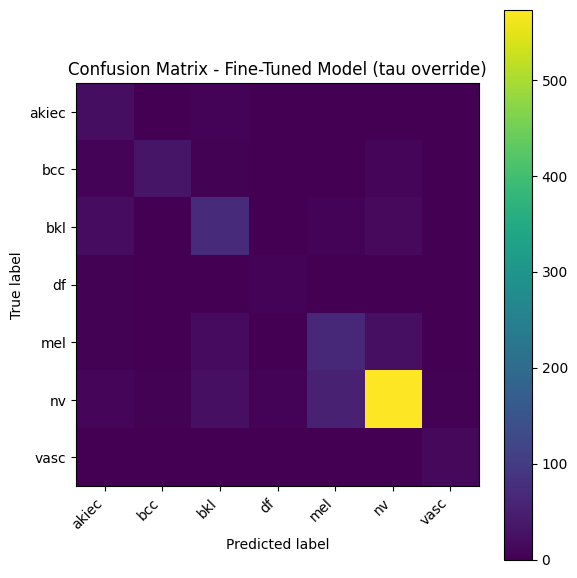

In [8]:
# compute and plot the confusion matrix for the test predictions
# This shows how well the fine-tuned model performs across all classes
# Including where misclassifications happen after applying the tau override

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true_idx, y_pred, labels = range(len(class_names)))
print(cm)

fig, ax = plt.subplots(figsize = (6, 6))
im = ax.imshow(cm, interpolation = "nearest")
ax.set_title("Confusion Matrix - Fine-Tuned Model (tau override)")
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation = 45, ha = "right")
ax.set_yticklabels(class_names)
plt.colorbar(im)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

## 9. PR Curve for Melanoma
This plot visualizes the precision-recall relationship for melanoma.
It helps justify why threshold tuning is needed to improve melanoma sensitivity.

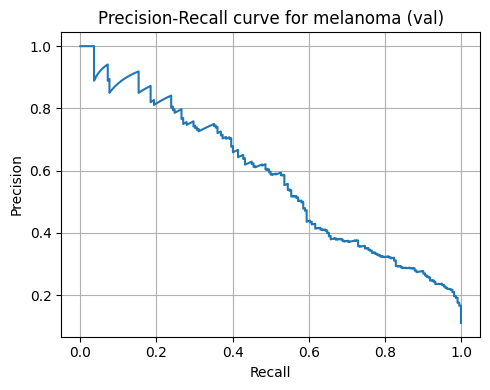

In [9]:
# Plot the Precision-Recall curve for melanoma on the validation set.
# This visualization the model's performance on the minority class
# helps determine the optimal tau threshold for melanoma detection

plt.figure(figsize = (5, 4))
plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve for melanoma (val)")
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. How to Test Functions
###. Test: Probability extraction
'''
probs, labels = get_probs_and_labels(test_loader, model)
print(probs.shape, labels.shape)
'''

### Test: Run threshold tuning again
'''
prec, rec, thr = precision_recall_curve(y_mel_true_val, mel_scores_val)
'''

### Test: Generate a confusion matrix
'''
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true_idx, y_pred)
print(cm()
'''

Each test verifies that your functions and pipeline behave correctly.

## 11. Summary of My Contribution
Implemented full HAM1000 preprocessing pipeline (file checks, stratified splitting, resizing).
Trained and evaluated two models: ResNet18 (baseline) and MobileNetV2 with focal loss (enhanced).
Implemented class balancing via class weights and weighted sampling.
Performed melanoma-specific threshold tuning using PR curves.
Generated evaluation outputs: classification reports, confusion matrix, PR curve.

These components complete the modeling portion of our group project.